## RDD - Resilient Distributed Dataset
Là cấu trúc dữ liệu phân tán nền tảng của Apache Spark.
- Resilient: Có khả năng khôi phục partition bị mất thông qua lineage.
- Distributed: Dữ liệu được chia thành nhiều partition.
- Dataset: Tập hợp các phần tử dữ liệu.
- Immutable: Không thay đổi trực tiếp dữ liệu của RDD hiện có; transformation tạo RDD mới.

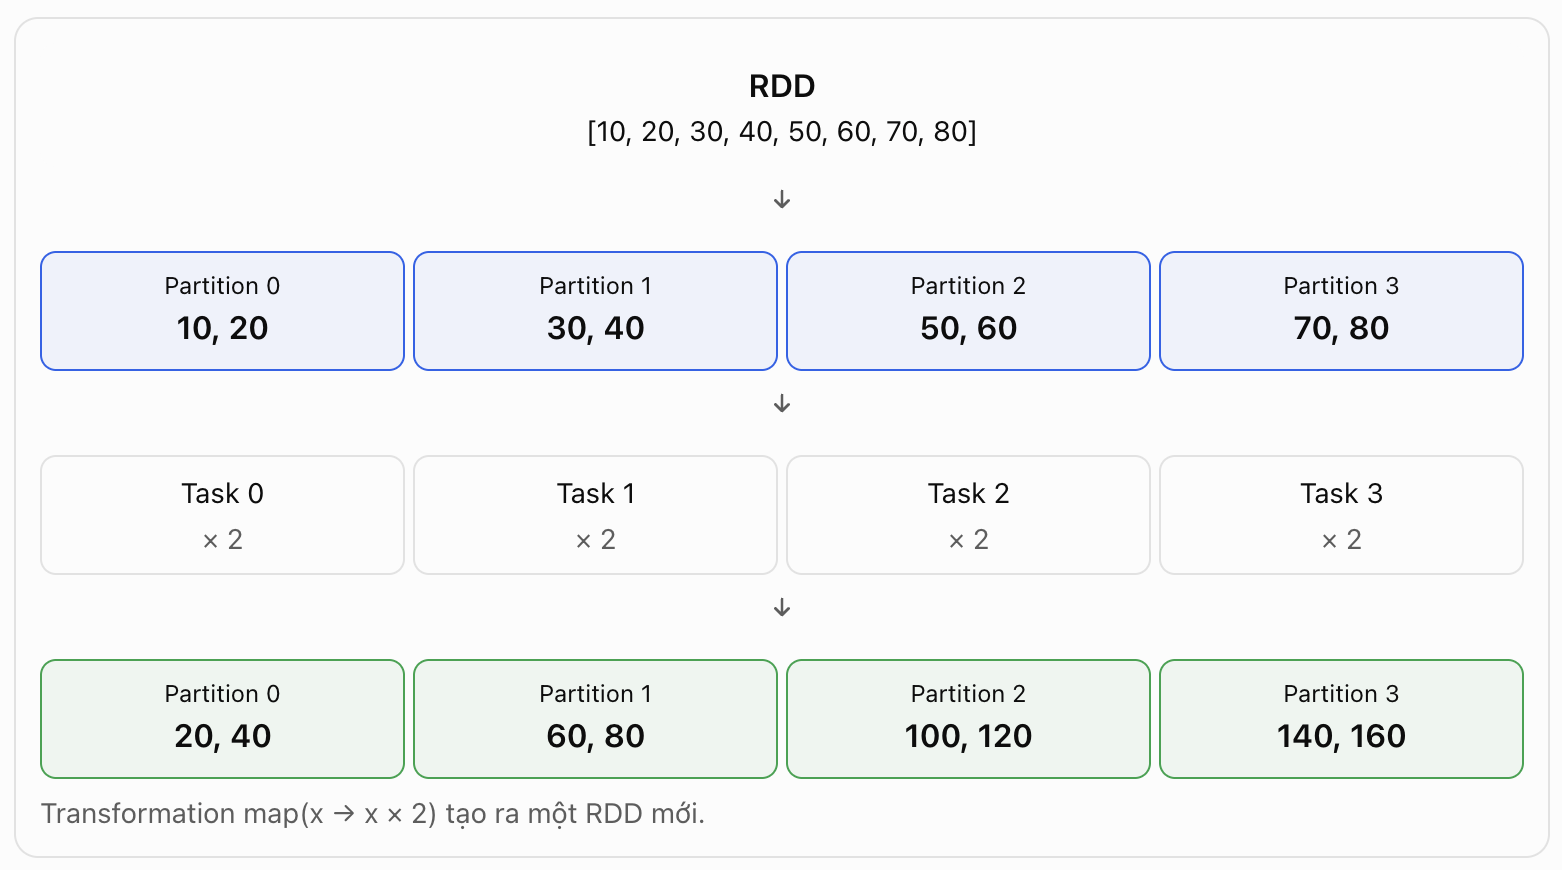

### RDD khác DataFrame

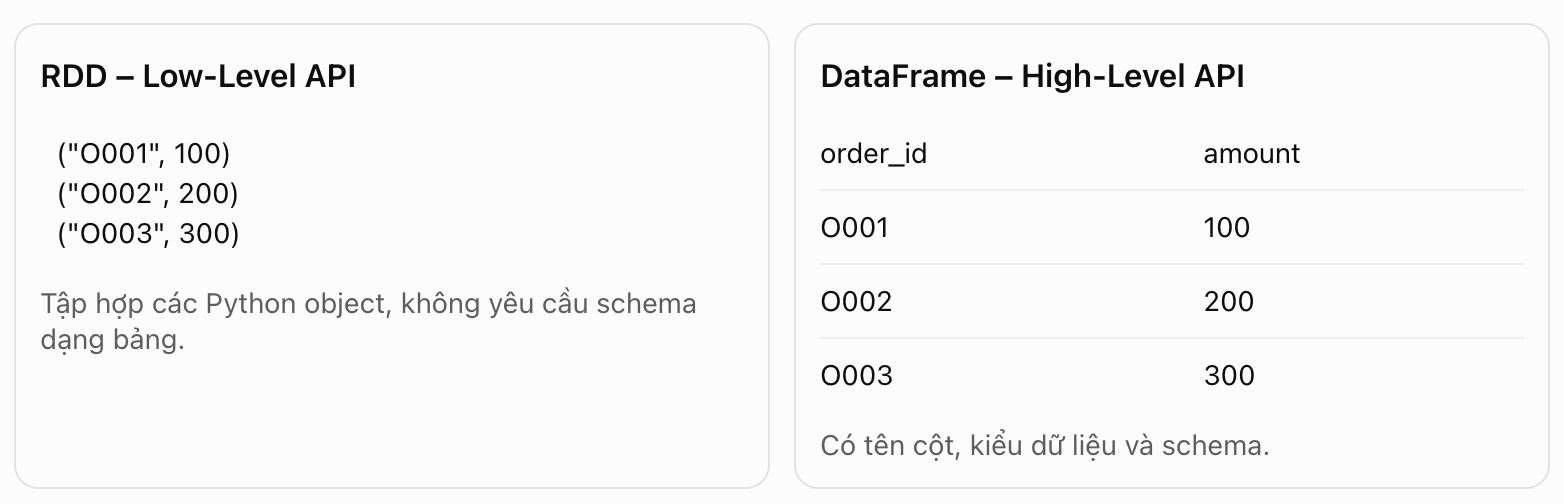

| Tiêu chí | RDD | DataFrame |
|---|---|---|
| API | Low-level | High-level |
| Schema | Không bắt buộc | Có |
| Catalyst Optimizer | Không tối ưu logic RDD | Có |
| Kiểm soát xử lý | Chi tiết | Mức trừu tượng cao |
| Dữ liệu | Các object | Dạng bảng có cấu trúc |
| Hiệu năng PySpark | Thường thấp hơn với xử lý dạng bảng | Thường tốt hơn |
| Ứng dụng | Logic tùy chỉnh, xử lý cấp partition | ETL, Analytics, SQL |

In [1]:
from pyspark.sql import SparkSession
from pathlib import Path

spark = (
    SparkSession.builder
    .appName("Phase02-RDD")
    .master("local[4]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

sc = spark.sparkContext
sc.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Spark UI:", sc.uiWebUrl)

26/11/25 13:58:57 WARN Utils: Your hostname, Thor-2.local resolves to a loopback address: 127.0.0.1; using 10.40.69.61 instead (on interface en0)
26/11/25 13:58:57 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/25 13:58:57 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.3
Spark UI: http://10.40.69.61:4040


## Các cách tạo RDD

### Tạo RDD từ Python collection

In [4]:
rdd = sc.parallelize(   # phân phối collection thành RDD
    [10, 20, 30, 40, 50, 60, 70, 80],
    4
)

print(rdd.collect())    # đưa toàn bộ kết quả về Driver
print(rdd.getNumPartitions())   # lấy số partition
print(rdd.glom().collect()) # Gom các phần tử trong mỗi partition thành 1 list

[10, 20, 30, 40, 50, 60, 70, 80]
4
[[10, 20], [30, 40], [50, 60], [70, 80]]


### Ba transformation quan trọng

#### map()
Biến đổi mỗi phần tử đầu vào thành một phần tử đầu ra.

In [5]:
mapped = rdd.map(lambda x: x * 2)

print(mapped.collect())

[20, 40, 60, 80, 100, 120, 140, 160]


### filter()
Chỉ giữ những phần tử thỏa mãn điều kiện.

In [6]:
filtered = rdd.filter(lambda x: x > 40)

print(filtered.collect())

[50, 60, 70, 80]


### flatMap()
Biến đổi một phần tử thành 0, 1 hoặc nhiều phần tử đầu ra.

In [8]:
# so sánh map và flatMap
sentences = sc.parallelize([
    "Spark Data Engineering",
    "Spark Big Data"
])

mapped_words = sentences.map(
    lambda x: x.split()
)

flat_words = sentences.flatMap(
    lambda x: x.split()
)

print("Map:", mapped_words.collect())
print("FlatMap:", flat_words.collect())

Map: [['Spark', 'Data', 'Engineering'], ['Spark', 'Big', 'Data']]
FlatMap: ['Spark', 'Data', 'Engineering', 'Spark', 'Big', 'Data']


### Web log
Khi người dùng truy cập một website, web server có thể ghi lại thông tin về request.

Ví dụ:

```text
10.1.1.10 2026-01-01T09:00:00 GET /products 200
```

| Thành phần | Giá trị |
|---|---|
| IP Address | `10.1.1.10` |
| Timestamp | `2026-01-01T09:00:00` |
| HTTP Method | `GET` |
| Endpoint | `/products` |
| Status Code | `200` |

Dữ liệu ban đầu chỉ là các dòng text. Chúng ta cần parse thành dữ liệu có cấu trúc trước khi phân tích.

### Sinh file web_logs.txt

In [10]:
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

logs_path = raw_dir / "web_logs.txt"

logs = [
    "10.1.1.10 2026-01-01T09:00:00 GET /products 200",
    "10.1.1.11 2026-01-01T09:01:00 GET /home 200",
    "10.2.1.10 2026-01-01T09:02:00 POST /cart 201",
    "10.3.1.10 2026-01-01T09:03:00 GET /products 200",
    "10.1.1.12 2026-01-01T09:04:00 POST /orders 201",
    "10.2.1.11 2026-01-01T09:05:00 GET /products 200",
    "10.3.1.11 2026-01-01T09:06:00 GET /home 200",
    "10.1.1.13 2026-01-01T09:07:00 GET /unknown 404",
    "10.2.1.12 2026-01-01T09:08:00 POST /orders 500",
    "10.9.1.10 2026-01-01T09:09:00 GET /products 200",
    "INVALID LOG",
    "10.1.1.14 broken_timestamp GET /home ABC"
]

logs_path.write_text(
    "\n".join(logs) + "\n",
    encoding="utf-8"
)

print(logs_path)

/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/web_logs.txt


### Đọc file bằng RDD

In [11]:
raw_logs = sc.textFile(
    str(logs_path),
    minPartitions=4
)

print("Total rows:", raw_logs.count())
print("Partitions:", raw_logs.getNumPartitions())

print(raw_logs.take(3))

Total rows: 12
Partitions: 4
['10.1.1.10 2026-01-01T09:00:00 GET /products 200', '10.1.1.11 2026-01-01T09:01:00 GET /home 200', '10.2.1.10 2026-01-01T09:02:00 POST /cart 201']


### Parsing dữ liệu

viết hàm parse_log

In [12]:
from datetime import datetime
from ipaddress import ip_address


def parse_log(line):
    parts = line.split()

    if len(parts) != 5:
        return None

    ip, timestamp, method, endpoint, status = parts

    try:
        ip_address(ip)

        datetime.fromisoformat(timestamp)

        status = int(status)

        if not 100 <= status <= 599:
            return None

        if method not in [
            "GET", "POST", "PUT",
            "DELETE", "PATCH", "HEAD", "OPTIONS"
        ]:
            return None

        return {
            "ip": ip,
            "timestamp": timestamp,
            "method": method,
            "endpoint": endpoint,
            "status": status
        }

    except ValueError:
        return None

In [13]:
parsed_logs = raw_logs.map(parse_log)

print(parsed_logs.take(2))

[{'ip': '10.1.1.10', 'timestamp': '2026-01-01T09:00:00', 'method': 'GET', 'endpoint': '/products', 'status': 200}, {'ip': '10.1.1.11', 'timestamp': '2026-01-01T09:01:00', 'method': 'GET', 'endpoint': '/home', 'status': 200}]


### Tách dữ liệu lỗi bằng filter

In [14]:
valid_logs = parsed_logs.filter(
    lambda x: x is not None
)

invalid_logs = parsed_logs.filter(
    lambda x: x is None
)

print("Valid:", valid_logs.count())
print("Invalid:", invalid_logs.count())

Valid: 10
Invalid: 2


### Làm tương tự với flatMap

In [15]:
def parse_valid_only(line):
    parsed = parse_log(line)

    if parsed is None:
        return []

    return [parsed]


valid_logs_v2 = raw_logs.flatMap(
    parse_valid_only
)

print(valid_logs_v2.count())

10


## Phân tích dữ liệu đơn giản

### Lọc các HTTP request bị lỗi

In [16]:
error_logs = valid_logs.filter(
    lambda log: log["status"] >= 400
)

error_logs.collect()

[{'ip': '10.1.1.13',
  'timestamp': '2026-01-01T09:07:00',
  'method': 'GET',
  'endpoint': '/unknown',
  'status': 404},
 {'ip': '10.2.1.12',
  'timestamp': '2026-01-01T09:08:00',
  'method': 'POST',
  'endpoint': '/orders',
  'status': 500}]

### Quan sát RDD Lineage

In [17]:
print(
    error_logs.toDebugString().decode("utf-8")
)

(4) PythonRDD[17] at collect at /var/folders/bg/hsvxykxj7yx0jz1nrhc3k6z40000gn/T/ipykernel_86360/641291314.py:5 []
 |  /Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/web_logs.txt MapPartitionsRDD[10] at textFile at NativeMethodAccessorImpl.java:0 []
 |  /Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/web_logs.txt HadoopRDD[9] at textFile at NativeMethodAccessorImpl.java:0 []


In [18]:
assert rdd.getNumPartitions() == 4

assert mapped.collect() == [
    20, 40, 60, 80, 100, 120, 140, 160
]

assert filtered.collect() == [50, 60, 70, 80]

assert mapped_words.count() == 2

assert flat_words.count() == 6

assert raw_logs.count() == 12

assert valid_logs.count() == 10

assert invalid_logs.count() == 2

assert (
    valid_logs.count() + invalid_logs.count()
    == raw_logs.count()
)

assert valid_logs.collect() == valid_logs_v2.collect()

assert error_logs.count() == 2

assert sorted(
    error_logs.map(
        lambda x: x["status"]
    ).collect()
) == [404, 500]

print("All 12 tests passed!")

All 12 tests passed!


### Shared Variables

Trong Spark, khi Driver gửi một task đến Executor, các biến bên ngoài được task sử dụng có thể được serialize và chuyển đến môi trường thực thi.

Vấn đề là nếu muốn chia sẻ một dictionary lớn cho nhiều task hoặc muốn tổng hợp một biến đếm từ nhiều Executor thì phải làm thế nào?

Spark cung cấp hai cơ chế:

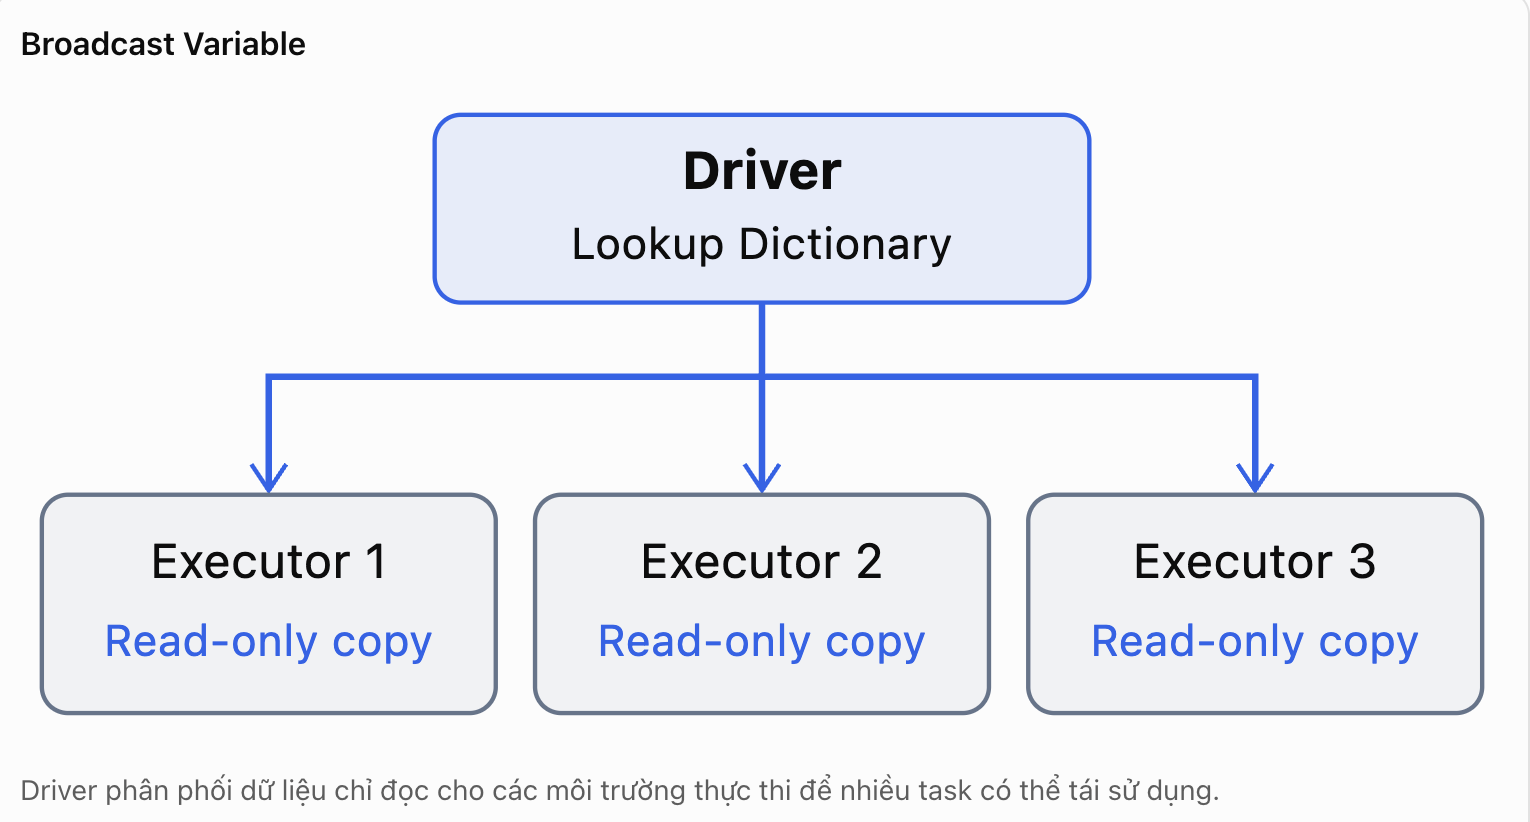

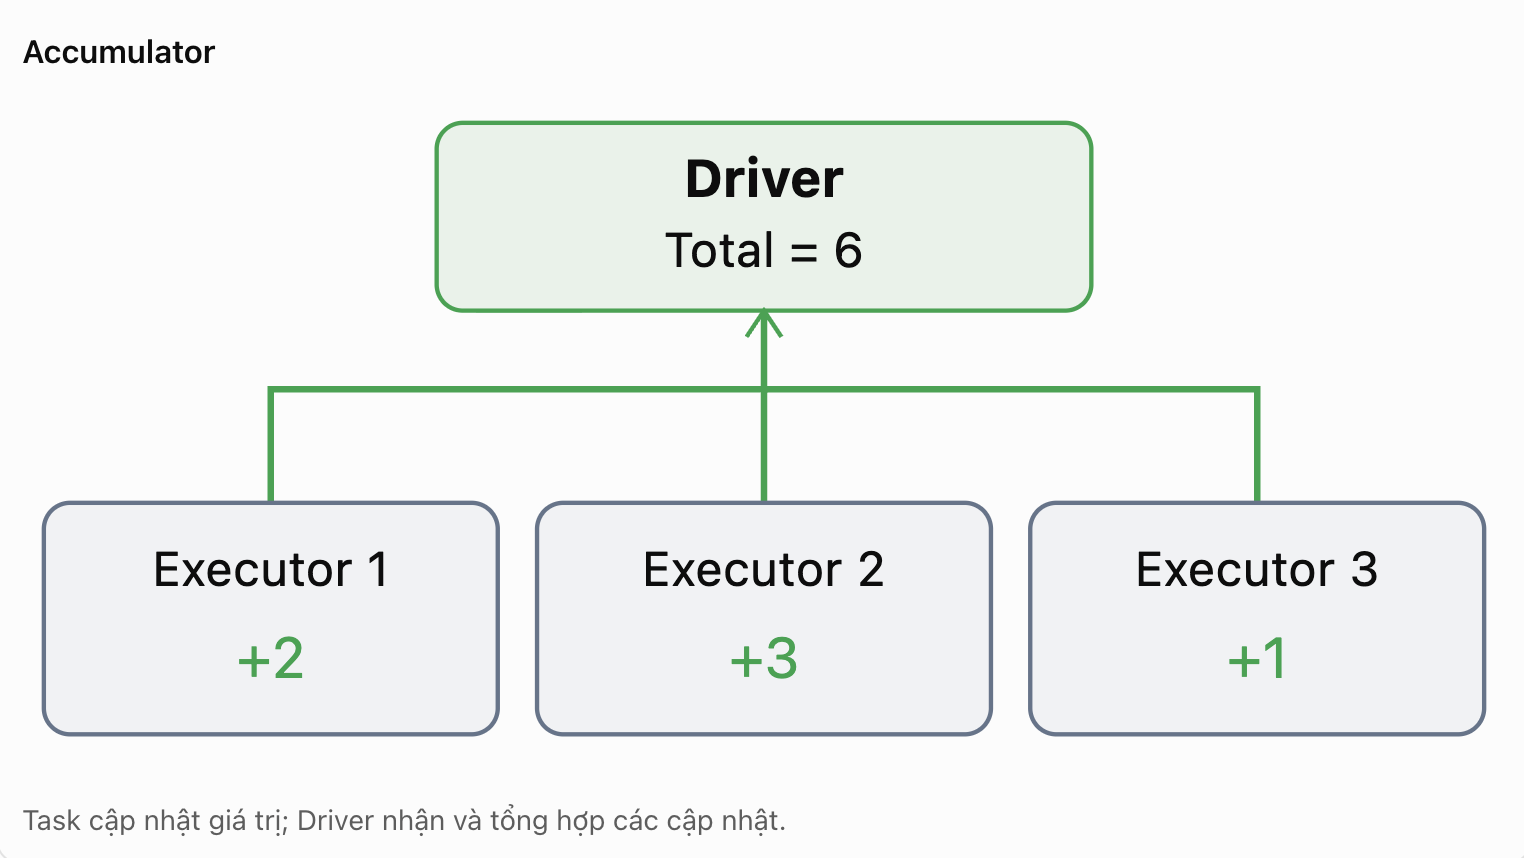

| Tiêu chí | Broadcast Variable | Accumulator |
|---|---|---|
| Hướng chia sẻ | Driver → Executor | Task → Driver |
| Mục đích | Chia sẻ dữ liệu | Tổng hợp giá trị |
| Task có thể đọc | Có | Không đọc giá trị tổng |
| Task có thể cập nhật | Không nên | Có, thông qua `add()` |
| Ví dụ | Lookup dictionary | Đếm log lỗi |